In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
import scipy.stats as stats
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer

In [44]:
df=pd.read_csv('train_titanic.csv',usecols=['Age','Fare','Survived'])

In [45]:
df

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500
...,...,...,...
886,0,27.0,13.0000
887,1,19.0,30.0000
888,0,NaN,23.4500
889,1,26.0,30.0000


In [51]:
df.isnull().sum()


Survived    0
Age         0
Fare        0
dtype: int64

In [50]:
df['Age'].fillna(df['Age'].mean())

0      22.000000
1      38.000000
2      26.000000
3      35.000000
4      35.000000
         ...    
886    27.000000
887    19.000000
888    29.699118
889    26.000000
890    32.000000
Name: Age, Length: 891, dtype: float64

In [48]:
x_train,x_test,y_train,y_test=train_test_split(df.drop(columns=['Survived']),df['Survived'],test_size=0.2,random_state=4)

Text(0.5, 1.0, 'Age qq plot')

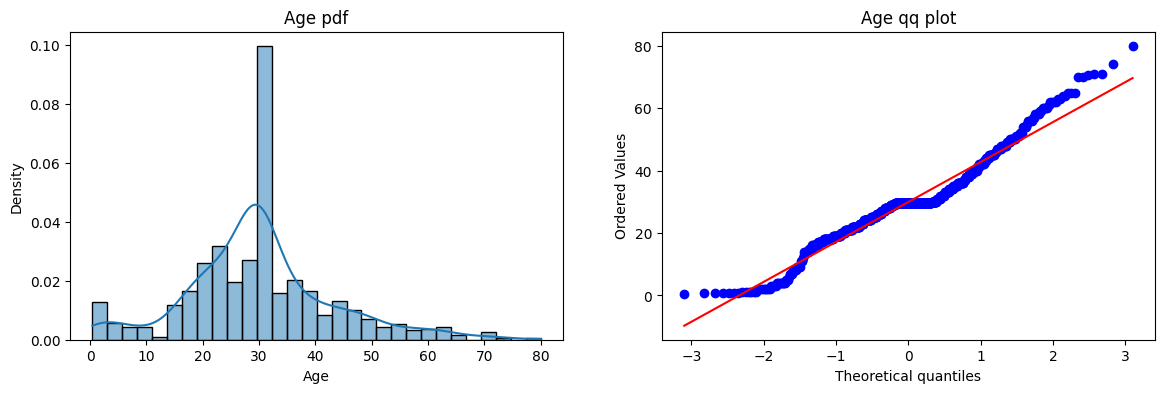

In [49]:
plt.figure(figsize=(14,4))
plt.subplot(1,2,1)
sns.histplot(x_train['Age'],stat='density',kde=True)
plt.title('Age pdf')
plt.subplot(1,2,2)
stats.probplot(x_train['Age'],dist='norm',plot=plt)
plt.title('Age qq plot')

Text(0.5, 1.0, 'Age qq plot')

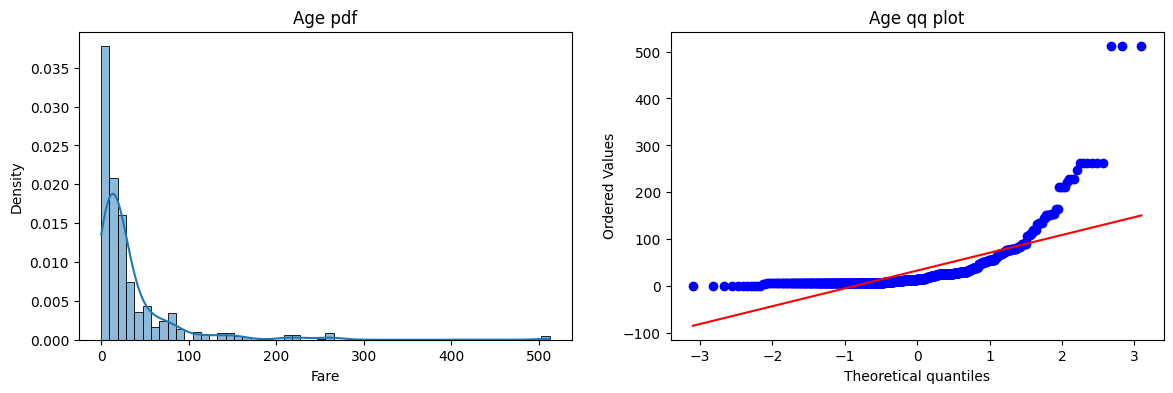

In [52]:
plt.figure(figsize=(14,4))
plt.subplot(1,2,1)
sns.histplot(x_train['Fare'],stat='density',kde=True)
plt.title('Age pdf')
plt.subplot(1,2,2)
stats.probplot(x_train['Fare'],dist='norm',plot=plt)
plt.title('Age qq plot')

In [53]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

In [55]:
clf.fit(x_train,y_train)
clf2.fit(x_train,y_train)
y_pred=clf.predict(x_test)
y_pred1=clf2.predict(x_test)
print('acc LR:',accuracy_score(y_test,y_pred))
print('acc DT:',accuracy_score(y_test,y_pred1))


acc LR: 0.6983240223463687
acc DT: 0.6759776536312849


In [56]:
trf=FunctionTransformer(func=np.log1p)
x_train_transformed=trf.fit_transform(x_train)
x_test_transformed=trf.transform(x_test)


In [57]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()
clf.fit(x_train_transformed,y_train)
clf2.fit(x_train_transformed,y_train)
y_pred = clf.predict(x_test_transformed)
y_pred1 = clf2.predict(x_test_transformed)
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred1))

Accuracy LR 0.6871508379888268
Accuracy DT 0.6759776536312849


In [60]:
x_transformed = trf.fit_transform(x_train)
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()
print("LR",np.mean(cross_val_score(clf,x_transformed,y_train,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,x_transformed,y_train,scoring='accuracy',cv=10)))

LR 0.6770344287949921
DT 0.6459702660406886


Text(0.5, 1.0, 'after Fare')

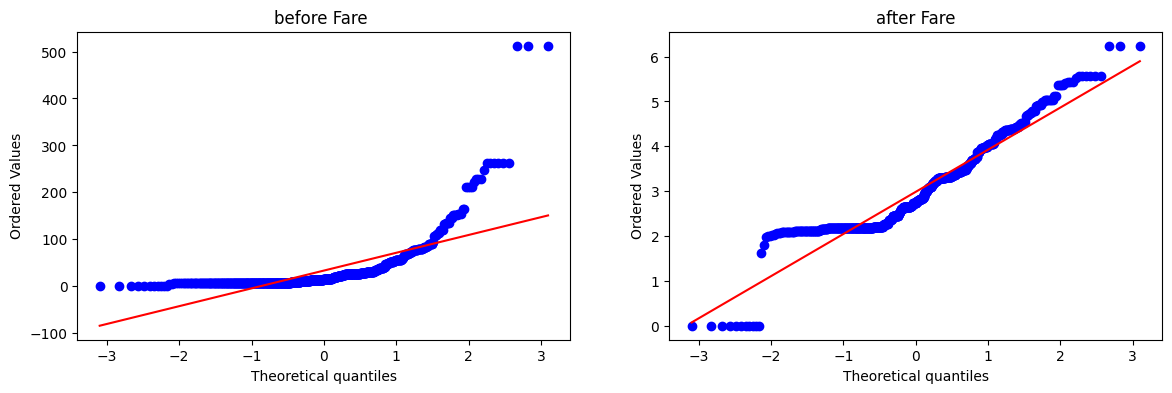

In [65]:
plt.figure(figsize=(14,4))
plt.subplot(1,2,1)
stats.probplot(x_train['Fare'],dist='norm',plot=plt)
plt.title('before Fare ')
plt.subplot(1,2,2)
stats.probplot(x_train_transformed['Fare'],dist='norm',plot=plt)
plt.title('after Fare')

Text(0.5, 1.0, 'after Age')

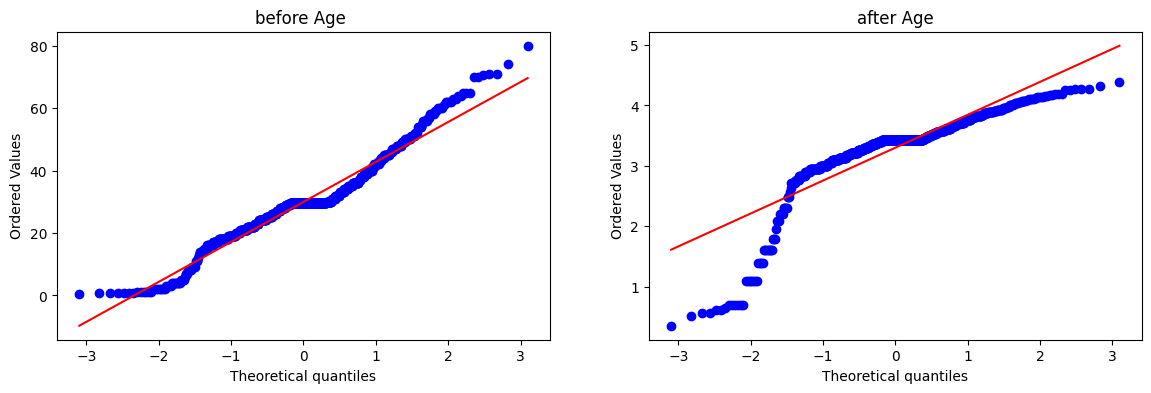

In [66]:
plt.figure(figsize=(14,4))
plt.subplot(1,2,1)
stats.probplot(x_train['Age'],dist='norm',plot=plt)
plt.title('before Age ')
plt.subplot(1,2,2)
stats.probplot(x_train_transformed['Age'],dist='norm',plot=plt)
plt.title('after Age')

In [67]:
trf2 = ColumnTransformer([('log',FunctionTransformer(np.log1p),['Fare'])],remainder='passthrough')
x_train_transformed2 = trf2.fit_transform(x_train)
x_test_transformed2 = trf2.transform(x_test)

In [68]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()
clf.fit(x_train_transformed2,y_train)
clf2.fit(x_train_transformed2,y_train)
y_pred = clf.predict(x_test_transformed2)
y_pred2 = clf2.predict(x_test_transformed2)
print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.6871508379888268
Accuracy DT 0.6759776536312849


In [70]:
x_transformed2 = trf2.fit_transform(x_train)
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()
print("LR",np.mean(cross_val_score(clf,x_transformed2,y_train,scoring='accuracy',cv=10)))
print("DT",np.mean(cross_val_score(clf2,x_transformed2,y_train,scoring='accuracy',cv=10)))

LR 0.6671948356807512
DT 0.6417057902973395


In [76]:
def apply_transform(transform):
    x = df.iloc[:,1:3]
    y = df.iloc[:,0]
    
    trf = ColumnTransformer([('log',FunctionTransformer(transform),['Fare'])],remainder='passthrough')
    
    x_trans = trf.fit_transform(x)
    
    clf = LogisticRegression()
    
    print("Accuracy",np.mean(cross_val_score(clf,x_trans,y,scoring='accuracy',cv=10)))
    
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(x['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(x_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

Accuracy 0.61729088639201


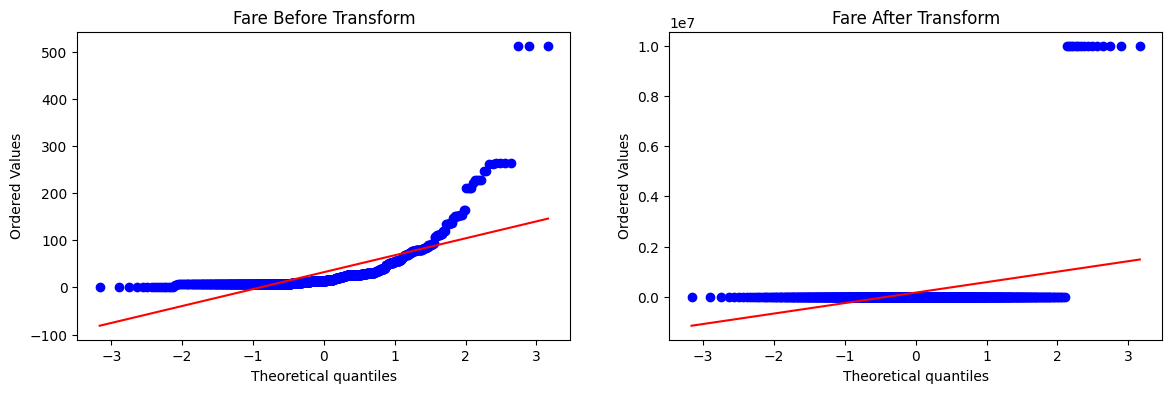

In [77]:
apply_transform(lambda x:1/(x+0.0000001))

Accuracy 0.6431335830212235


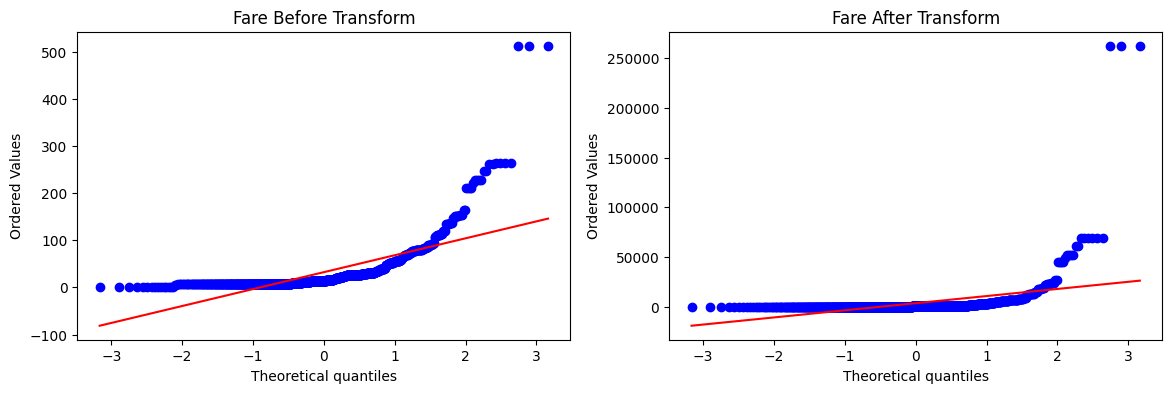

In [78]:
apply_transform(lambda x:x**2)

Accuracy 0.6589013732833957


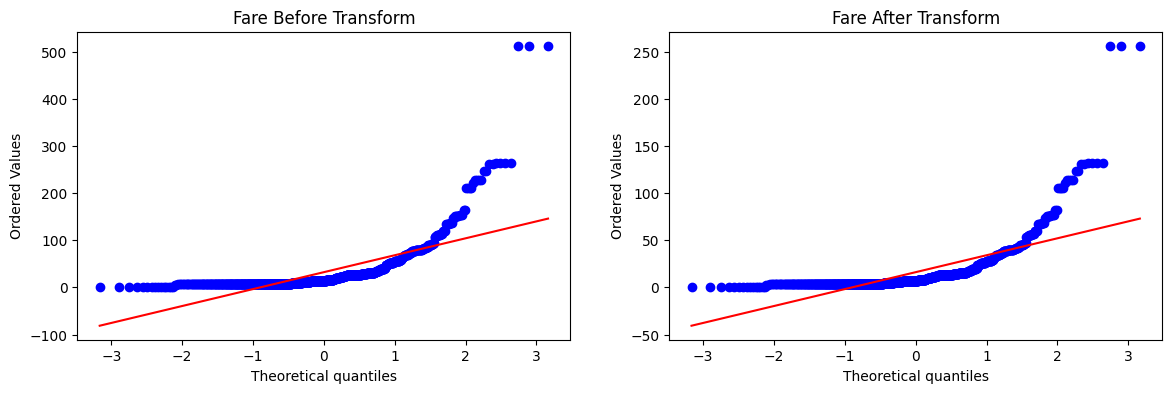

In [79]:
apply_transform(lambda x:x**1/2)